Environment

In [1]:
libs = {
    "hypernet": "/home/zanardi/Codes/TC/HyperNet/hypernet",
    "pycomet": "/home/zanardi/Codes/ML/PyCOMET/pycomet"
}

In [2]:
import sys
for lib in libs.values():
    sys.path.append(lib)

Import libraries

In [3]:
import os
import json
import copy
import pycomet
import numpy as np
import scipy as sp

from scipy.linalg import expm
from silx.io.dictdump import h5todict

from hypernet import const
from hypernet.apps import utils as hyputils
from hypernet.thermophysics import specie_thermo as st_mod

Plotting

In [4]:
import matplotlib
from matplotlib import pyplot as plt
COLORS = matplotlib.rcParams['axes.prop_cycle'].by_key()['color']

path_to_figs = "./figs/"
os.makedirs(path_to_figs, exist_ok=True)

def plot_var(
    x=None,
    y=None,
    xref=None,
    yref=None,
    labels=[r'$t$ [s]', r'$X$'],
    scales=['log', 'log'],
    names=None,
    figname=None
):
    # Initialize figures
    fig = plt.figure()
    ax = fig.add_subplot()
    # x axis
    ax.set_xlabel(labels[0])
    ax.set_xscale(scales[0])
    # y axis
    ax.set_ylabel(labels[1])
    ax.set_yscale(scales[1])
    # Plotting
    n, d = y.shape if (x is not None) else yref.shape
    true_style = dict(
        lw=1
    )
    pred_style = dict(
        marker='^',
        fillstyle='none',
        markersize=5,
        markevery=n//20,
        ls='--',
        lw=1
    )
    for i in range(d):
        if (x is not None):
            ax.plot(x, y[:,i], c=COLORS[i], **pred_style)
        if (xref is not None):
            ax.plot(xref, yref[:,i], c=COLORS[i], **true_style)
        ax.plot([], [], c=COLORS[i], label=names[i])
    # plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    plt.legend()
    if (figname is not None):
        fig.savefig(figname)
    plt.show()
    plt.close()

Initializing thermophysical models

In [5]:
with open("./../physics/inputs.full.json") as file:
    phyinp = json.load(file)
# Species thermo
sp_th = hyputils._get_specie_thermos(phyinp)
# Mixture
mix = hyputils._get_mixture(phyinp, sp_th)
# Kinetics
kin = hyputils._get_kinetics(phyinp, sp_th, mix)

Exact solution

In [6]:
def get_data(solution):
    t, T = [solution[k] for k in ('t', 'T')]
    na, nm = [solution[f"X_{s}"] * solution['n'] for s in sp_th.keys()]
    return t, na, nm, T

In [7]:
sol = h5todict(h5file='./../physics/solutions/full/solution.p1k.T1k.O05.hdf5')

In [8]:
t, na, nm, T = get_data(sol)
n = np.hstack([na, nm])
kin._update(n, T)

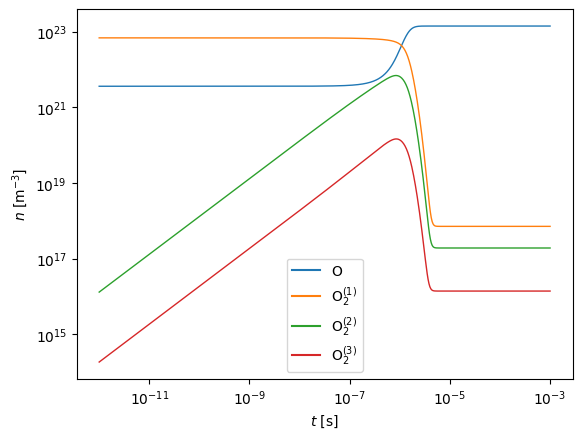

In [9]:
plot_var(
    xref=t.squeeze()[1:],
    yref=n[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'log'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(3)],
    figname=path_to_figs + "/solution"
)

Construct rate matrices

In [93]:
ke = 0.0
for reaction in kin.reactions:
    if (reaction.param['process'] in (5,6)):
        ke = ke + reaction.fwd.k.numpy().squeeze()[0]
        ke = ke + reaction.bwd.k.numpy().squeeze()[0].T
    elif (reaction.param['process'] == 2):
        kd = reaction.fwd.k.numpy().squeeze()[0]
        kr = reaction.bwd.k.numpy().squeeze()[0]
ke = (ke.T - np.diag(np.sum(ke, axis=-1)))

In [11]:
s, V = sp.linalg.eig(ke*na[0])

In [12]:
interg = lambda t, n: V @ np.diag(np.exp(t*s)) @ sp.linalg.inv(V) @ n

In [13]:
n_pred2 = np.vstack([interg(ti,nm[0]) for ti in t])
n_pred2

array([[ 6.88082199e+22+0.j,  8.48431392e+10+0.j, -3.78686843e+04+0.j],
       [ 6.88082065e+22+0.j,  1.31726307e+16+0.j,  1.86819058e+14+0.j],
       [ 6.88082063e+22+0.j,  1.34490154e+16+0.j,  1.90738886e+14+0.j],
       ...,
       [ 5.34364547e+22+0.j,  1.43285852e+22+0.j,  1.04318003e+21+0.j],
       [ 5.34364547e+22+0.j,  1.43285852e+22+0.j,  1.04318003e+21+0.j],
       [ 5.34364547e+22+0.j,  1.43285852e+22+0.j,  1.04318003e+21+0.j]])

In [14]:
def exc_int(t, na, nm):
    k = sp.linalg.expm(t*ke*na)
    nm = np.matmul(k, nm)
    return nm

In [15]:
n_pred1 = np.vstack([exc_int(ti,na[0],nm[0]) for ti in t])
n_pred1

array([[6.88082199e+22, 8.48471976e+10, 1.71261139e-02],
       [6.88082065e+22, 1.31726307e+16, 1.86819058e+14],
       [6.88082063e+22, 1.34490154e+16, 1.90738886e+14],
       ...,
       [5.34364547e+22, 1.43285852e+22, 1.04318003e+21],
       [5.34364547e+22, 1.43285852e+22, 1.04318003e+21],
       [5.34364547e+22, 1.43285852e+22, 1.04318003e+21]])

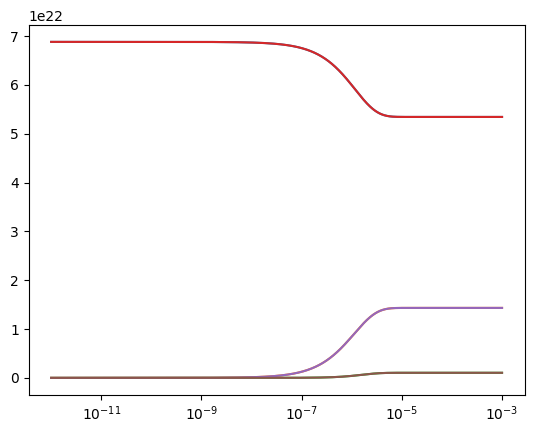

In [16]:
plt.semilogx(t[1:], n_pred2[1:])
plt.semilogx(t[1:], n_pred1[1:])

Define integrals
> Full system

In [17]:
def ful_fun(t, c):
    f = np.zeros_like(c)
    # Extract number densities
    n = c * const.UNA
    na, nm = n[0:1], n[1:]
    # Construct source terms
    we = np.matmul(ke,nm*na)
    wd = kd*nm*na - kr*na**3
    # Compose source terms
    f[0] = 2*np.sum(wd)
    f[1:] = we - wd
    return f / const.UNA

def ful_int(t, n0):
    res = sp.integrate.solve_ivp(
        fun=ful_fun,
        t_span=[t[0],t[-1]],
        t_eval=t.squeeze(),
        y0=n0/const.UNA,
        method='LSODA',
        atol=1e-9,
        rtol=1e-7
    )
    return res.y.T * const.UNA

In [18]:
n_full = ful_int(t, n[0])

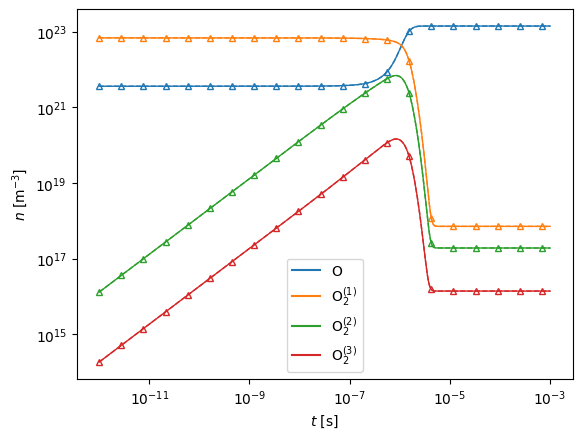

In [19]:
plot_var(
    x=t.squeeze()[1:],
    y=n_full[1:],
    xref=t.squeeze()[1:],
    yref=n[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'log'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(3)],
    figname=path_to_figs + "/solution"
)

> Linear system

In [20]:
def exc_int(t, na, nm):
    k = sp.linalg.expm(t*ke*na)
    nm = np.matmul(k, nm)
    return na, nm

In [32]:
def fullin_fun(t, c):
    f = np.zeros_like(c)
    # Extract number densities
    n = c * const.UNA
    na, nm = n[0:1], n[1:]
    # Construct source terms
    we = np.matmul(ke,nm*na)
    wd = kd*nm*na - kr*na**3
    # Compose source terms
    f[1:] = we - wd
    return f / const.UNA

def fullin_int(t, n0):
    res = sp.integrate.solve_ivp(
        fun=fullin_fun,
        t_span=[t[0],t[-1]],
        t_eval=t.squeeze(),
        y0=n0/const.UNA,
        method='LSODA',
        atol=1e-15,
        rtol=1e-12
    )
    return res.y.T * const.UNA

In [86]:
kf, kb = 0.0, 0.0
for reaction in kin.reactions:
    if (reaction.param['process'] in (5,6)):
        kf = kf + reaction.fwd.k.numpy().squeeze()[0]
        kb = kb + reaction.bwd.k.numpy().squeeze()[0]
    elif (reaction.param['process'] == 2):
        kd = reaction.fwd.k.numpy().squeeze()[0]
        kr = reaction.bwd.k.numpy().squeeze()[0]

In [122]:
na = n[0,0]
qc = np.random.rand(1,3)
# qc = np.ones((1,3))
kec = kf*qc + (kb*qc).T
kec = (kec.T - np.diag(np.sum(kec, axis=-1)))
kdc = kd*qc.squeeze()
krc = kr*qc.squeeze()
kc = kec - np.diag(kdc)

In [125]:
kc = (kec - np.diag(kdc))*na
k = (ke - np.diag(kd))*na
wr = krc*na**3
ki = np.linalg.inv(k)

In [129]:
kc @ ki @ wr

array([ 1.65345828e+18,  7.07880175e+19, -1.78612997e+18])

In [54]:
k = ke - np.diag(kd)
I = np.eye(3)

In [71]:
qc = np.random.rand(1,3)

array([[0.        , 0.50726641, 0.50726641],
       [0.        , 0.        , 0.16786492],
       [0.        , 0.        , 0.        ]])

In [76]:
qc = np.random.rand(3,1)
kec = ke * qc
kec

array([[0.00000000e+00, 4.54187533e-17, 6.44147222e-19],
       [3.78151851e-17, 0.00000000e+00, 5.95214134e-18],
       [2.49089613e-17, 2.76447518e-16, 0.00000000e+00]])

In [69]:

ke = (ke.T - np.diag(np.sum(ke, axis=-1)))

array([[0., 1., 1.],
       [0., 0., 1.],
       [0., 0., 0.]])

In [58]:
na = n[0,0]
ki = np.linalg.inv(k*n[0,0])
k*na @ ki

array([[ 1.00000000e+00, -1.18496563e-16,  2.09544721e-17],
       [ 2.85858598e-16,  1.00000000e+00,  6.49572541e-19],
       [ 9.22555068e-18,  2.07641954e-17,  1.00000000e+00]])

In [51]:
def fullin_int_anal(t, n):
    # Extract number densities
    na, nm = n[0:1], n[1:]
    # Construct source terms
    wr = kr*na**3
    # Construct solution operator
    ek = sp.linalg.expm(t*k*na)
    ki = np.linalg.inv(k*na)
    # Compute solution 
    nm = ek@nm+(ek-I)@ki@wr
    return np.concatenate([na,nm])

In [52]:
n_fullin = fullin_int(t, n[0])
n_fullin_anal = np.vstack([fullin_int_anal(ti, n[0]) for ti in t])

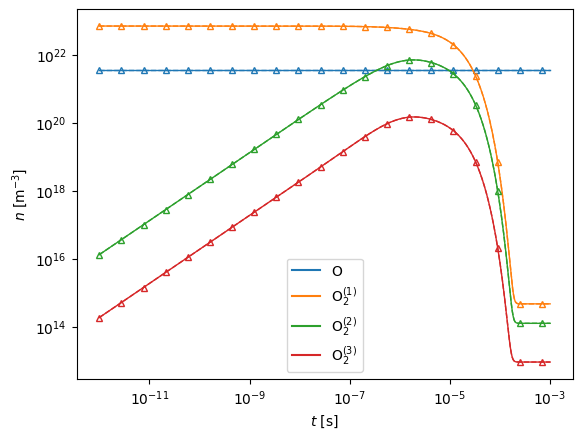

In [53]:
plot_var(
    x=t.squeeze()[1:],
    y=n_fullin_anal[1:],
    xref=t.squeeze()[1:],
    yref=n_fullin[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'log'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(3)],
    figname=path_to_figs + "/solution"
)

> Non-linear system

In [ ]:
def dis_fun(t, c, kd, kr):
    f = np.zeros_like(c)
    # Extract number densities
    n = c * const.UNA
    # Construct source terms
    wd = kd*n[0]*n[1] - kr*n[0]**3
    # Compose source terms
    f[0] = 2*wd
    f[1] = -wd
    return f / const.UNA

def dis_int(t, na, nm):
    nms = np.sum(nm, keepdims=True)
    xm = nm / nms
    n0 = np.concatenate([na, nms])
    res = sp.integrate.solve_ivp(
        fun=dis_fun,
        t_span=[0,t],
        y0=n0/const.UNA,
        method='LSODA',
        args=(np.sum(kd*xm), np.sum(kr)),
        atol=1e-9,
        rtol=1e-7
    )
    n = res.y[:,-1] * const.UNA
    na, nm = n[0:1], n[1:2]*xm
    return na, nm

In [ ]:
def dis_fun(t, c):
    f = np.zeros_like(c)
    # Extract number densities
    n = c * const.UNA
    na, nm = n[0:1], n[1:]
    # Construct source terms
    wd = kd*nm*na - kr*na**3
    # Compose source terms
    f[0] = 2*np.sum(wd)
    f[1:] = - wd
    return f / const.UNA

def dis_int(t, na, nm):
    n0 = np.concatenate([na, nm])
    res = sp.integrate.solve_ivp(
        fun=dis_fun,
        t_span=[0,t],
        y0=n0/const.UNA,
        method='LSODA',
        atol=1e-9,
        rtol=1e-7
    )
    n = res.y[:,-1] * const.UNA
    return n[0:1], n[1:]

> Operator splitting

In [ ]:
def integrate(t, n0, na):
    y = [n0]
    # na, nm = n0[0:1], n0[1:]
    nm = n0
    
    m = np.sum(n0, axis=-1, keepdims=True)*2 + na[0]
    for (i, ti) in enumerate(t[1:]):
        # Step 0: Define time step
        dt = ti - t[i]
        # Step 1: Integrate exc. for dt/2
        xm = nm / np.sum(nm, axis=-1, keepdims=True)
        _, xm = exc_int(dt, na[i], xm)
        nm = (m - na[i]) * xm * 0.5
        # Step 2: Integrate dis. for dt
        # na, nm = dis_int(dt, na, nm)
        # Step 3: Integrate exc. for dt/2
        # _, nm = exc_int(dt/2, na[i+1], nm)
        # # Step 4: Store solution
        # n = np.concatenate([na, nm])
        y.append(nm)
    return np.vstack(y)

In [ ]:
t_split = np.array([0] + np.logspace(-8,-4,300).tolist())
# t_split = np.arange(0,1e-4,1e-8)
t_split = t

In [ ]:
n_split = integrate(t_split, n[0,1:], na)
n_split = np.hstack([na, n_split])

In [ ]:
plot_var(
    x=t_split.squeeze()[1:],
    y=n_split[1:],
    xref=t.squeeze()[1:],
    yref=n[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'log'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(3)],
    figname=path_to_figs + "/solution"
)